# Image classification — quickstart

**Classification** assigns one label to a whole image: *which of these N classes is this?* Here the classes are three shapes; the same code classifies steel defects, plant diseases, or anything you can sort into folders.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 1 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/classification/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("classification", cfg)
print("task:", "classification", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: classification | data: data/demo/classification | outputs: outputs/classification_quick


## 1 · The data
A few examples, with their labels:

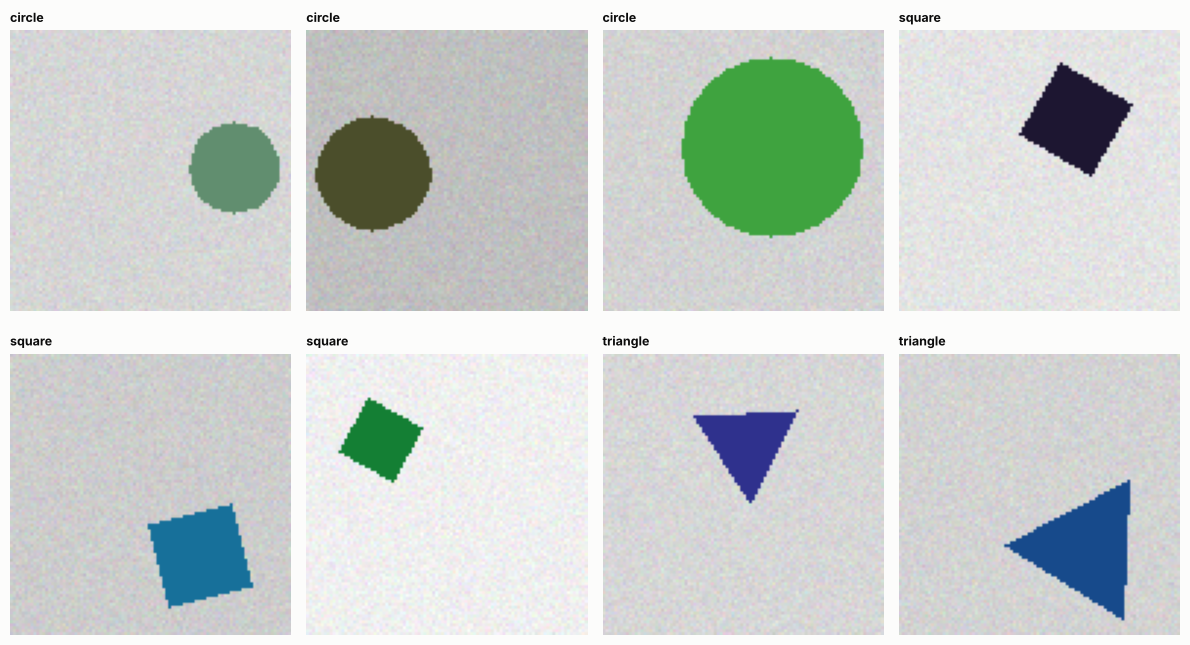

In [3]:
from PIL import Image
from cvkit.viz import image_grid
from tasks.classification.data import build_datasets

ds = build_datasets(cfg)
classes, samples = ds["classes"], ds["samples"]
picks = samples[::max(len(samples) // 8, 1)][:8]
_ = image_grid([Image.open(p) for p, _ in picks], [classes[t] for _, t in picks], cols=4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit classification train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.classification.train import train

result = train(cfg)

arch: resnet18 | classes (3): ['circle', 'square', 'triangle']
device: cpu | parameters: 11,178,051 total, 11,178,051 trainable (100.0%)


epoch   1/15 | train_loss 1.3312 | val loss=3.963 acc=0.409 | 3.0s  <- best


epoch   2/15 | train_loss 0.9955 | val loss=1.158 acc=0.409 | 3.5s


epoch   3/15 | train_loss 1.0097 | val loss=0.877 acc=0.576 | 2.9s  <- best


epoch   4/15 | train_loss 0.9431 | val loss=1.043 acc=0.424 | 3.0s


...

epoch  11/15 | train_loss 0.2555 | val loss=0.183 acc=0.970 | 2.9s


epoch  12/15 | train_loss 0.2391 | val loss=0.053 acc=0.985 | 3.1s


epoch  13/15 | train_loss 0.2762 | val loss=0.047 acc=0.985 | 2.8s


epoch  14/15 | train_loss 0.2451 | val loss=0.039 acc=0.985 | 2.9s


epoch  15/15 | train_loss 0.2272 | val loss=0.047 acc=0.985 | 2.9s
best val acc = 0.9848 (epoch 10) -> outputs/classification_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.classification.evaluate import evaluate

metrics = evaluate(cfg)

test accuracy: 0.9848 | macro-F1: 0.9848 (66 images)
              precision    recall  f1-score   support

      circle      0.957     1.000     0.978        22
      square      1.000     0.955     0.977        22
    triangle      1.000     1.000     1.000        22

    accuracy                          0.985        66
   macro avg      0.986     0.985     0.985        66
weighted avg      0.986     0.985     0.985        66

reports -> outputs/classification_quick/reports


confusion_matrix.png


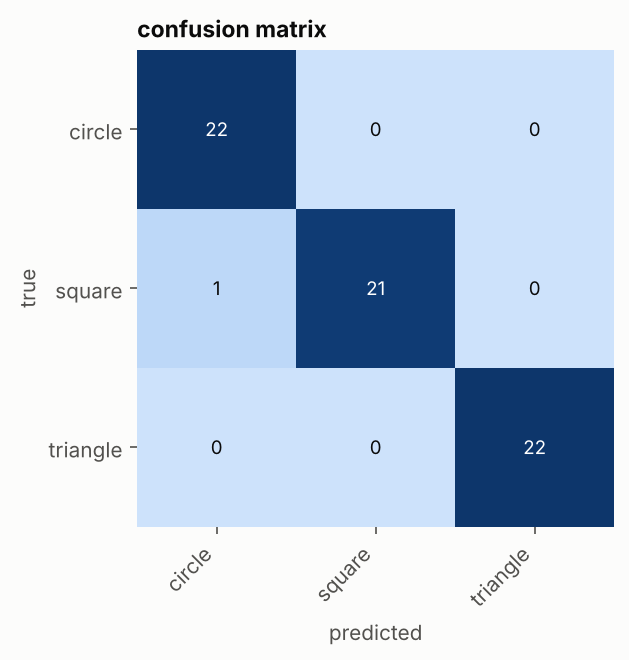

top_losses.png


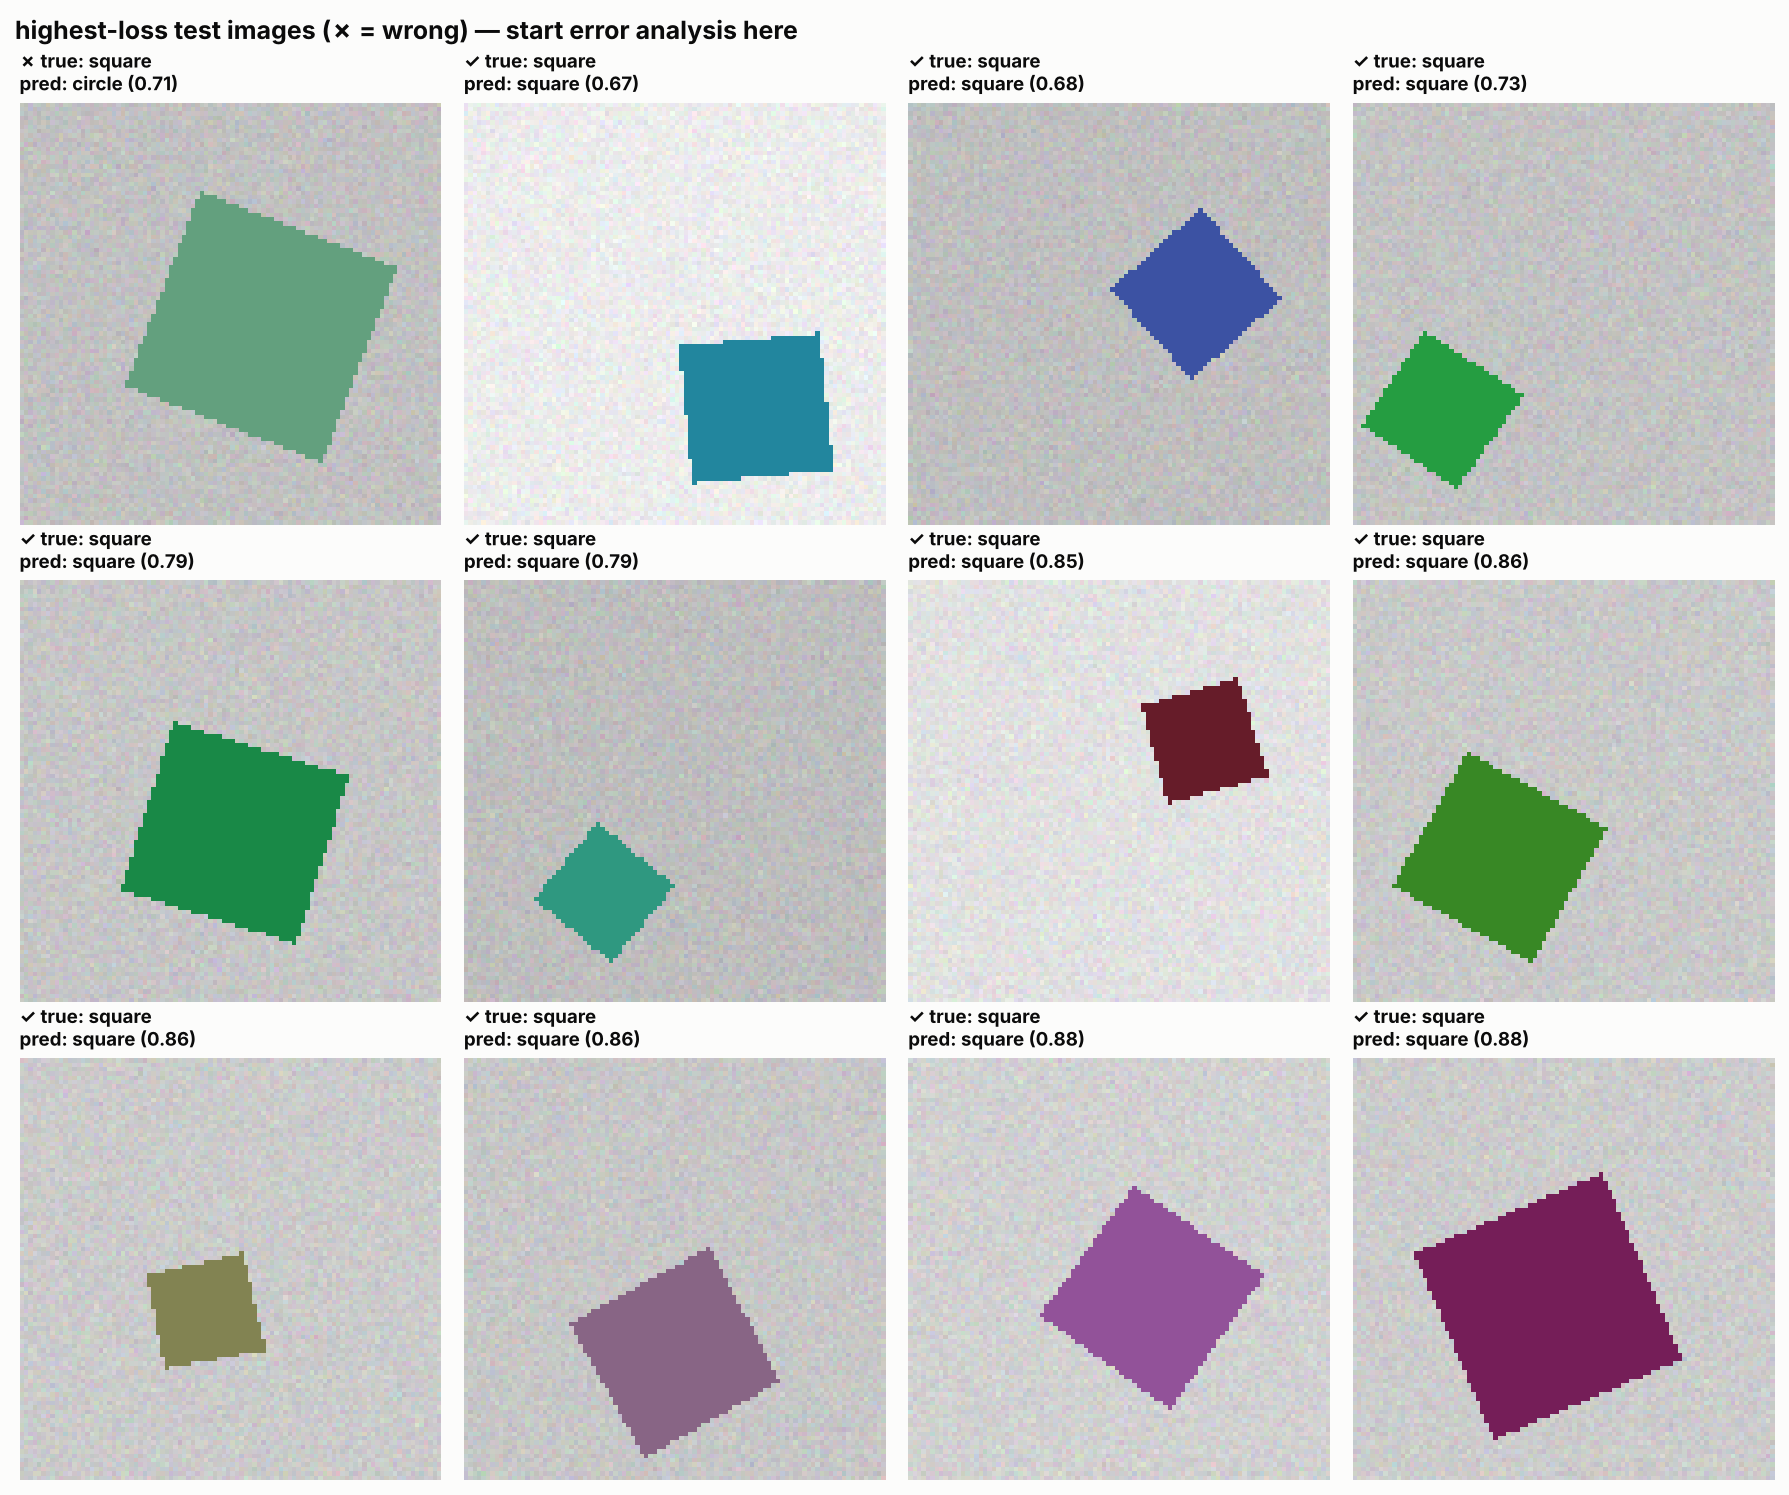

In [6]:
from IPython.display import Image as IPImage, display

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['confusion_matrix.png', 'top_losses.png']:
    print(name)
    display(IPImage(filename=str(reports / name)))

**Reading it:** the confusion matrix puts the true class on the rows and the predicted class on the columns — a bright diagonal means correct. `top_losses.png` shows the test images the model was most wrong (or least sure) about; ✗ marks real mistakes.

## 4 · Predict
`Predictor` loads the saved model and returns the top classes with probabilities:

In [7]:
from tasks.classification.predict import Predictor
from tasks.classification.data import test_image_paths

predictor = Predictor.from_config(cfg)
for path in test_image_paths(cfg, 4):
    top = predictor.predict(path, top_k=3)
    print(Path(path).name, "->", ", ".join(f"{p['label']} {p['confidence']:.2f}" for p in top))

img_0014.png -> circle 1.00, triangle 0.00, square 0.00
img_0034.png -> circle 1.00, triangle 0.00, square 0.00
img_0137.png -> circle 0.99, square 0.01, triangle 0.00
img_0010.png -> circle 1.00, triangle 0.00, square 0.00


## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)